In [1]:
#https://github.com/Erdenetuya610/Statistical-Tech-2026.git

In [2]:
!pip install ucimlrepo pandas

In [3]:
from scipy.stats import norm
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns
import sklearn

In [4]:
from ucimlrepo import fetch_ucirepo
df=fetch_ucirepo(id=350).data.original
df.head()

,ID,X1,X2,X3,X4,X5,X6,X7,X8,X9,...,X15,X16,X17,X18,X19,X20,X21,X22,X23,Y
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [5]:
df.shape

(30000, 25)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   ID      30000 non-null  int64
 1   X1      30000 non-null  int64
 2   X2      30000 non-null  int64
 3   X3      30000 non-null  int64
 4   X4      30000 non-null  int64
 5   X5      30000 non-null  int64
 6   X6      30000 non-null  int64
 7   X7      30000 non-null  int64
 8   X8      30000 non-null  int64
 9   X9      30000 non-null  int64
 10  X10     30000 non-null  int64
 11  X11     30000 non-null  int64
 12  X12     30000 non-null  int64
 13  X13     30000 non-null  int64
 14  X14     30000 non-null  int64
 15  X15     30000 non-null  int64
 16  X16     30000 non-null  int64
 17  X17     30000 non-null  int64
 18  X18     30000 non-null  int64
 19  X19     30000 non-null  int64
 20  X20     30000 non-null  int64
 21  X21     30000 non-null  int64
 22  X22     30000 non-null  int64
 23  X23     300

#Check for missing values

In [7]:
df.isnull().sum()

ID     0
X1     0
X2     0
X3     0
X4     0
X5     0
X6     0
X7     0
X8     0
X9     0
X10    0
X11    0
X12    0
X13    0
X14    0
X15    0
X16    0
X17    0
X18    0
X19    0
X20    0
X21    0
X22    0
X23    0
Y      0
dtype: int64

In [8]:
df.duplicated()

0        False
1        False
2        False
3        False
4        False
         ...  
29995    False
29996    False
29997    False
29998    False
29999    False
Length: 30000, dtype: bool

In [9]:
df.describe()

,ID,X1,X2,X3,X4,X5,X6,X7,X8,X9,...,X15,X16,X17,X18,X19,X20,X21,X22,X23,Y
count,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,...,30000.000000,30000.000000,30000.000000,30000.000000,3.000000e+04,30000.00000,30000.000000,30000.000000,30000.000000,30000.000000
mean,15000.500000,167484.322667,1.603733,1.853133,1.551867,35.485500,-0.016700,-0.133767,-0.166200,-0.220667,...,43262.948967,40311.400967,38871.760400,5663.580500,5.921163e+03,5225.68150,4826.076867,4799.387633,5215.502567,0.221200
std,8660.398374,129747.661567,0.489129,0.790349,0.521970,9.217904,1.123802,1.197186,1.196868,1.169139,...,64332.856134,60797.155770,59554.107537,16563.280354,2.304087e+04,17606.96147,15666.159744,15278.305679,17777.465775,0.415062
min,1.000000,10000.000000,1.000000,0.000000,0.000000,21.000000,-2.000000,-2.000000,-2.000000,-2.000000,...,-170000.000000,-81334.000000,-339603.000000,0.000000,0.000000e+00,0.00000,0.000000,0.000000,0.000000,0.000000
25%,7500.750000,50000.000000,1.000000,1.000000,1.000000,28.000000,-1.000000,-1.000000,-1.000000,-1.000000,...,2326.750000,1763.000000,1256.000000,1000.000000,8.330000e+02,390.00000,296.000000,252.500000,117.750000,0.000000
50%,15000.500000,140000.000000,2.000000,2.000000,2.000000,34.000000,0.000000,0.000000,0.000000,0.000000,...,19052.000000,18104.500000,17071.000000,2100.000000,2.009000e+03,1800.00000,1500.000000,1500.000000,1500.000000,0.000000
75%,22500.250000,240000.000000,2.000000,2.000000,2.000000,41.000000,0.000000,0.000000,0.000000,0.000000,...,54506.000000,50190.500000,49198.250000,5006.000000,5.000000e+03,4505.00000,4013.250000,4031.500000,4000.000000,0.000000
max,30000.000000,1000000.000000,2.000000,6.000000,3.000000,79.000000,8.000000,8.000000,8.000000,8.000000,...,891586.000000,927171.000000,961664.000000,873552.000000,1.684259e+06,896040.00000,621000.000000,426529.000000,528666.000000,1.000000


In [10]:
df.columns

Index(['ID', 'X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'X7', 'X8', 'X9', 'X10',
       'X11', 'X12', 'X13', 'X14', 'X15', 'X16', 'X17', 'X18', 'X19', 'X20',
       'X21', 'X22', 'X23', 'Y'],
      dtype='object')

In [11]:
#rename columns 
df.rename(columns={
    'ID':'ID',
    'X1':'LIMIT_BAL',
    'X2':'SEX',
    'X3':'EDUCATION',
    'X4':'MARRIAGE',
    'X5':'AGE'
}, inplace=True)
df.describe()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,X6,X7,X8,X9,...,X15,X16,X17,X18,X19,X20,X21,X22,X23,Y
count,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,...,30000.000000,30000.000000,30000.000000,30000.000000,3.000000e+04,30000.00000,30000.000000,30000.000000,30000.000000,30000.000000
mean,15000.500000,167484.322667,1.603733,1.853133,1.551867,35.485500,-0.016700,-0.133767,-0.166200,-0.220667,...,43262.948967,40311.400967,38871.760400,5663.580500,5.921163e+03,5225.68150,4826.076867,4799.387633,5215.502567,0.221200
std,8660.398374,129747.661567,0.489129,0.790349,0.521970,9.217904,1.123802,1.197186,1.196868,1.169139,...,64332.856134,60797.155770,59554.107537,16563.280354,2.304087e+04,17606.96147,15666.159744,15278.305679,17777.465775,0.415062
min,1.000000,10000.000000,1.000000,0.000000,0.000000,21.000000,-2.000000,-2.000000,-2.000000,-2.000000,...,-170000.000000,-81334.000000,-339603.000000,0.000000,0.000000e+00,0.00000,0.000000,0.000000,0.000000,0.000000
25%,7500.750000,50000.000000,1.000000,1.000000,1.000000,28.000000,-1.000000,-1.000000,-1.000000,-1.000000,...,2326.750000,1763.000000,1256.000000,1000.000000,8.330000e+02,390.00000,296.000000,252.500000,117.750000,0.000000
50%,15000.500000,140000.000000,2.000000,2.000000,2.000000,34.000000,0.000000,0.000000,0.000000,0.000000,...,19052.000000,18104.500000,17071.000000,2100.000000,2.009000e+03,1800.00000,1500.000000,1500.000000,1500.000000,0.000000
75%,22500.250000,240000.000000,2.000000,2.000000,2.000000,41.000000,0.000000,0.000000,0.000000,0.000000,...,54506.000000,50190.500000,49198.250000,5006.000000,5.000000e+03,4505.00000,4013.250000,4031.500000,4000.000000,0.000000
max,30000.000000,1000000.000000,2.000000,6.000000,3.000000,79.000000,8.000000,8.000000,8.000000,8.000000,...,891586.000000,927171.000000,961664.000000,873552.000000,1.684259e+06,896040.00000,621000.000000,426529.000000,528666.000000,1.000000


In [12]:
df.describe(include='all')

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,X6,X7,X8,X9,...,X15,X16,X17,X18,X19,X20,X21,X22,X23,Y
count,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,...,30000.000000,30000.000000,30000.000000,30000.000000,3.000000e+04,30000.00000,30000.000000,30000.000000,30000.000000,30000.000000
mean,15000.500000,167484.322667,1.603733,1.853133,1.551867,35.485500,-0.016700,-0.133767,-0.166200,-0.220667,...,43262.948967,40311.400967,38871.760400,5663.580500,5.921163e+03,5225.68150,4826.076867,4799.387633,5215.502567,0.221200
std,8660.398374,129747.661567,0.489129,0.790349,0.521970,9.217904,1.123802,1.197186,1.196868,1.169139,...,64332.856134,60797.155770,59554.107537,16563.280354,2.304087e+04,17606.96147,15666.159744,15278.305679,17777.465775,0.415062
min,1.000000,10000.000000,1.000000,0.000000,0.000000,21.000000,-2.000000,-2.000000,-2.000000,-2.000000,...,-170000.000000,-81334.000000,-339603.000000,0.000000,0.000000e+00,0.00000,0.000000,0.000000,0.000000,0.000000
25%,7500.750000,50000.000000,1.000000,1.000000,1.000000,28.000000,-1.000000,-1.000000,-1.000000,-1.000000,...,2326.750000,1763.000000,1256.000000,1000.000000,8.330000e+02,390.00000,296.000000,252.500000,117.750000,0.000000
50%,15000.500000,140000.000000,2.000000,2.000000,2.000000,34.000000,0.000000,0.000000,0.000000,0.000000,...,19052.000000,18104.500000,17071.000000,2100.000000,2.009000e+03,1800.00000,1500.000000,1500.000000,1500.000000,0.000000
75%,22500.250000,240000.000000,2.000000,2.000000,2.000000,41.000000,0.000000,0.000000,0.000000,0.000000,...,54506.000000,50190.500000,49198.250000,5006.000000,5.000000e+03,4505.00000,4013.250000,4031.500000,4000.000000,0.000000
max,30000.000000,1000000.000000,2.000000,6.000000,3.000000,79.000000,8.000000,8.000000,8.000000,8.000000,...,891586.000000,927171.000000,961664.000000,873552.000000,1.684259e+06,896040.00000,621000.000000,426529.000000,528666.000000,1.000000


In [13]:
# Mean credit limit
mean = df['LIMIT_BAL'].mean()
print("Mean credit limit:", mean)

# Mean age
mean_age = df['AGE'].mean()
print("Mean age:", mean_age)

# Mean education
mean_education = df['EDUCATION'].mean()
print("Mean education:", mean_education)


Mean credit limit: 167484.32266666667
Mean age: 35.4855
Mean education: 1.8531333333333333


In [14]:
# Median credit limit
median = df['LIMIT_BAL'].median()
print("Median credit limit:", median)

# Median age
median_age = df['AGE'].median()
print("Median age:", median_age)

# Median education
median_education = df['EDUCATION'].median()
print("Median education:", median_education)

Median credit limit: 140000.0
Median age: 34.0
Median education: 2.0


In [15]:
# Mode credit limit
mode = df['LIMIT_BAL'].mode()
print("Mean credit limit:", mode)

# Mode age
mode_age = df['AGE'].mode()
print("Mean age:", mode_age)

# Mode education
mode_education = df['EDUCATION'].mode()
print("Mean education:", mode_education)

Mean credit limit: 0    50000
Name: LIMIT_BAL, dtype: int64
Mean age: 0    29
Name: AGE, dtype: int64
Mean education: 0    2
Name: EDUCATION, dtype: int64


Plot the distribution

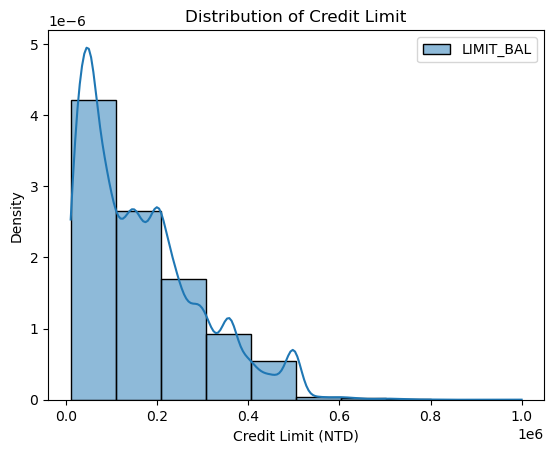

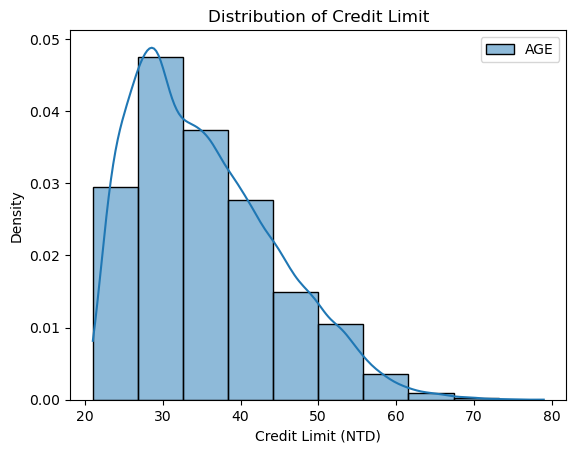

In [16]:
data = df['LIMIT_BAL']

sns.histplot(data,bins=10,stat='density',kde=True,label='LIMIT_BAL')

plt.title('Distribution of Credit Limit')
plt.xlabel('Credit Limit (NTD)')
plt.ylabel('Density')
plt.legend()
plt.show()

data = df['AGE']

sns.histplot(data,bins=10,stat='density',kde=True,label='AGE')

plt.title('Distribution of Credit Limit')
plt.xlabel('Credit Limit (NTD)')
plt.ylabel('Density')
plt.legend()
plt.show()

min to max values, and variance

In [17]:
# Minimum credit limit
print("Minimum:", df['LIMIT_BAL'].min())

# Maximum credit limit
print("Maximum:", df['LIMIT_BAL'].max())

# Range
print("Range:", df['LIMIT_BAL'].max() - df['LIMIT_BAL'].min())

# Variance
print("Variance:", df['LIMIT_BAL'].var())


# Minimum credit limit
print("Minimum:", df['AGE'].min())

# Maximum credit limit
print("Maximum:", df['AGE'].max())

# Range
print("Range:", df['AGE'].max() - df['AGE'].min())

# Variance
print("Variance:", df['AGE'].var())


Minimum: 10000
Maximum: 1000000
Range: 990000
Variance: 16834455682.155386
Minimum: 21
Maximum: 79
Range: 58
Variance: 84.96975540851355


standart deviaton and Median 

In [18]:
# Standard Deviation
print("Standard Deviation:", df['LIMIT_BAL'].std())

# Median (50th percentile)
print("Median:", df['LIMIT_BAL'].median())

# Quantiles
print("25th percentile (0.25):", df['LIMIT_BAL'].quantile(0.25))
print("75th percentile (0.75):", df['LIMIT_BAL'].quantile(0.75))

Standard Deviation: 129747.66156719506
Median: 140000.0
25th percentile (0.25): 50000.0
75th percentile (0.75): 240000.0


Хэмжигдэхүүн	Тайлбар
Standard Deviation	Зээлийн лимитүүд дунджаасаа хэр зэрэг хэлбэлзэж байгааг харуулна.
Median	Өгөгдлийн голд байрлах утга буюу 50-р перцентиль.
0.25	25% нь энэ утгатай тэнцүү эсвэл бага байна.
0.50	50% нь энэ утгатай тэнцүү эсвэл бага байна — медиан.
0.75	75% нь энэ утгатай тэнцүү эсвэл бага байна.
25-р ба 75-р перцентилийн зөрүүг IQR (Interquartile Range) гэдэг.

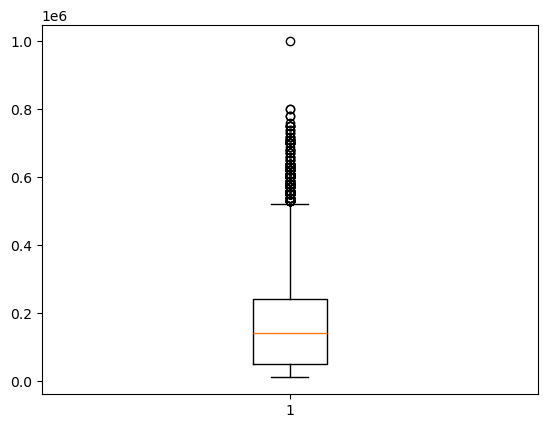

In [19]:
plt.boxplot(df['LIMIT_BAL'])
plt.show()

In [20]:
# Select credit limit data
data = df['LIMIT_BAL'].dropna()

# Calculate mean and standard deviation
mu = data.mean()
sigma = data.std()

print("Mean (mu):", mu)
print("Standard Deviation (sigma):", sigma)
print("Skewness:", data.skew())
print("Kurtosis:", data.kurtosis())

Mean (mu): 167484.32266666667
Standard Deviation (sigma): 129747.66156719506
Skewness: 0.992866960519544
Kurtosis: 0.536262896398668


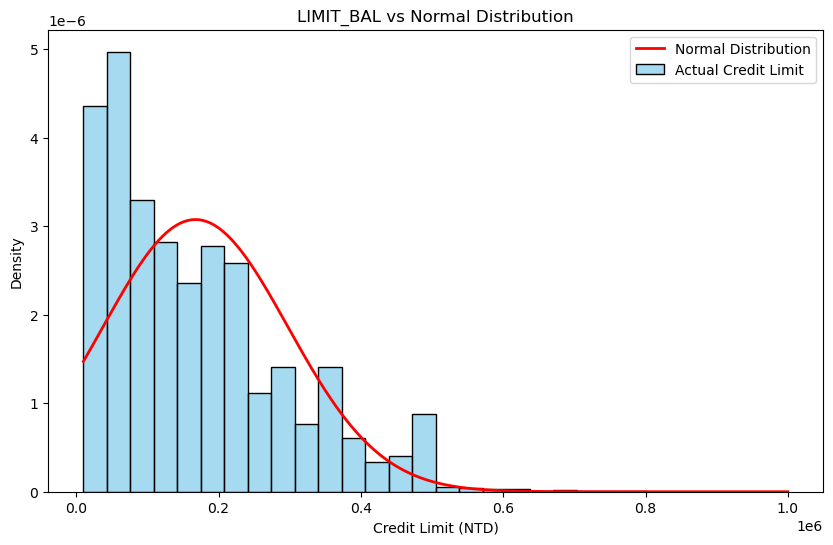

In [21]:
data = df['LIMIT_BAL'].dropna()

mu = data.mean()
sigma = data.std()

plt.figure(figsize=(10, 6))

sns.histplot(
    data,
    bins=30,
    stat='density',
    color='skyblue',
    label='Actual Credit Limit'
)

x = np.linspace(data.min(), data.max(), 1000)

plt.plot(
    x,
    norm.pdf(x, mu, sigma),
    color='red',
    linewidth=2,
    label='Normal Distribution'
)

plt.title('LIMIT_BAL vs Normal Distribution')
plt.xlabel('Credit Limit (NTD)')
plt.ylabel('Density')
plt.legend()
plt.show()
    

Гол ажиглалт
1. Цэнхэр багануудын ихэнх нь зүүн талд буюу харьцангуй бага зээлийн лимит дээр төвлөрсөн байна.
2. Тархалт баруун тийш урт сүүлтэй байгаа нь эерэг хазайлт (positive skewness)-ыг харуулна.
3. Улаан муруй бодит тархалттай бүрэн тохирохгүй байна. Иймээс LIMIT_BAL нь хэвийн тархалтаас мэдэгдэхүйц ялгаатай харагдаж байна.

   Normal Distribution Analysis of LIMIT_BAL

The histogram shows the actual distribution of credit limits among clients, while the red curve represents a theoretical normal distribution based on the sample mean and standard deviation.

The actual distribution is positively skewed, with most observations concentrated at lower credit limits and a long tail extending towards higher values. The normal curve does not closely match the histogram, indicating that the credit limit data may not follow a normal distribution.

Therefore, the visual comparison suggests that LIMIT_BAL is not normally distributed. This conclusion can be further supported by examining the skewness value, a Q-Q plot, and a normality test.

In [23]:
print("Skewness:", df['LIMIT_BAL'].skew())
print("Kurtosis:", df['LIMIT_BAL'].kurtosis())

Skewness: 0.992866960519544
Kurtosis: 0.536262896398668
